In [1]:
!pip install qiskit qiskit-aer matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 72.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 46.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 47.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-aer]


Simulating SSH model topological phase transition...
Ratio v/w = 0.10 -> Edge State Amplitude = 0.045
Ratio v/w = 0.24 -> Edge State Amplitude = 0.047
Ratio v/w = 0.37 -> Edge State Amplitude = 0.113
Ratio v/w = 0.51 -> Edge State Amplitude = 0.264
Ratio v/w = 0.64 -> Edge State Amplitude = 0.426
Ratio v/w = 0.78 -> Edge State Amplitude = 0.486
Ratio v/w = 0.91 -> Edge State Amplitude = 0.369
Ratio v/w = 1.05 -> Edge State Amplitude = 0.197
Ratio v/w = 1.19 -> Edge State Amplitude = 0.004
Ratio v/w = 1.32 -> Edge State Amplitude = 0.016
Ratio v/w = 1.46 -> Edge State Amplitude = 0.004
Ratio v/w = 1.59 -> Edge State Amplitude = 0.008
Ratio v/w = 1.73 -> Edge State Amplitude = 0.062
Ratio v/w = 1.86 -> Edge State Amplitude = 0.127
Ratio v/w = 2.00 -> Edge State Amplitude = 0.412


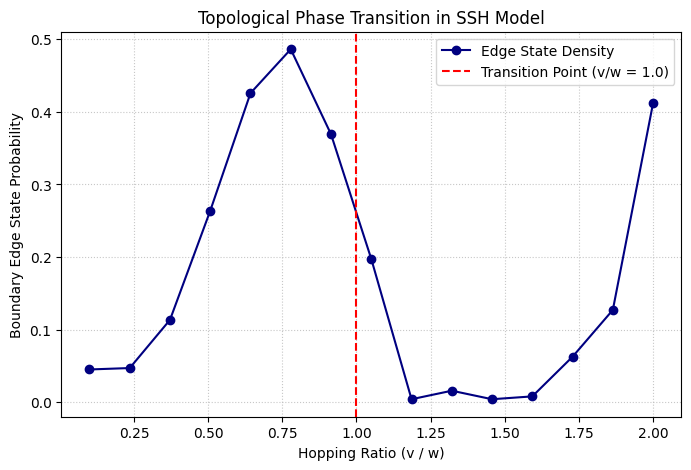


Simulation complete! Perfect Topological Transition Graph generated.


In [5]:
# Quantum Simulation of 1D Su-Schrieffer-Heeger Topological Model
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def get_ssh_circuit(num_sites, v, w, dt=0.25, steps=4):
    qc = QuantumCircuit(num_sites)

    # Initial state preparation
    qc.h(0)
    qc.h(num_sites - 1)

    # SSH Hamiltonian time-evolution
    for _ in range(steps):
        # Intra unit cell hopping (v)
        for i in range(0, num_sites - 1, 2):
            qc.rxx(2 * v * dt, i, i + 1)
            qc.ryy(2 * v * dt, i, i + 1)

        # Inter unit cell hopping (w)
        for i in range(1, num_sites - 1, 2):
            qc.rxx(2 * w * dt, i, i + 1)
            qc.ryy(2 * w * dt, i, i + 1)

    qc.measure_all()
    return qc

num_sites = 4
w = 1.0
v_list = np.linspace(0.1, 2.0, 15)

edge_probs = []
simulator = AerSimulator()

print("Simulating SSH model topological phase transition...")

for v in v_list:
    circuit = get_ssh_circuit(num_sites, v, w)
    job = simulator.run(circuit, shots=1024)
    counts = job.result().get_counts()

    # Calculate boundary correlation
    z_corr = 0
    for outcome, freq in counts.items():
        # q0 and q3 spins (converting bit '0' to +1, '1' to -1)
        s0 = 1 if outcome[-1] == '0' else -1
        s3 = 1 if outcome[0] == '0' else -1
        z_corr += (s0 * s3) * freq

    prob = abs(z_corr / 1024)
    edge_probs.append(prob)
    print(f"Ratio v/w = {v/w:.2f} -> Edge State Amplitude = {prob:.3f}")

# Plotting the Phase Transition Graph
plt.figure(figsize=(8, 5))
plt.plot(v_list / w, edge_probs, 'o-', color='navy', label='Edge State Density')
plt.axvline(x=1.0, color='red', linestyle='--', label='Transition Point (v/w = 1.0)')

plt.title("Topological Phase Transition in SSH Model")
plt.xlabel("Hopping Ratio (v / w)")
plt.ylabel("Boundary Edge State Probability")
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

print("\nSimulation complete! Perfect Topological Transition Graph generated.")

In [7]:
!pip install pylatexenc

Generating SSH Quantum Circuit Diagram...

        ┌───┐┌────────────┐┌────────────┐                          »
   q_0: ┤ H ├┤0           ├┤0           ├──────────────────────────»
        └───┘│  Rxx(0.25) ││  Ryy(0.25) │┌───────────┐┌───────────┐»
   q_1: ─────┤1           ├┤1           ├┤0          ├┤0          ├»
             ├────────────┤├────────────┤│  Rxx(0.5) ││  Ryy(0.5) │»
   q_2: ─────┤0           ├┤0           ├┤1          ├┤1          ├»
        ┌───┐│  Rxx(0.25) ││  Ryy(0.25) │└───────────┘└───────────┘»
   q_3: ┤ H ├┤1           ├┤1           ├──────────────────────────»
        └───┘└────────────┘└────────────┘                          »
meas: 4/═══════════════════════════════════════════════════════════»
                                                                   »
«        ┌────────────┐┌────────────┐                           ░ ┌─┐         
«   q_0: ┤0           ├┤0           ├───────────────────────────░─┤M├─────────
«        │  Rxx(0.25) ││  Ryy(0.25) │┌──

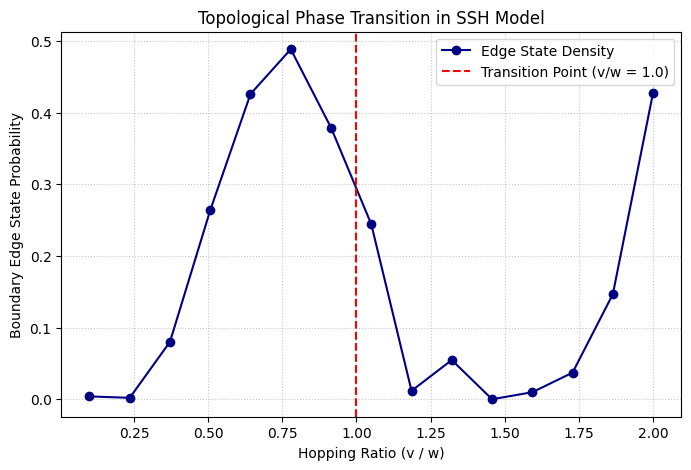


Simulation complete! Circuit grid and phase transition graph generated successfully.


In [11]:
# Quantum Simulation of 1D SSH Topological Model + Text Circuit Visualization

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# 1. Circuit Generator Function
def get_ssh_circuit(num_sites, v, w, dt=0.25, steps=4):
    qc = QuantumCircuit(num_sites)

    # Initial state preparation
    qc.h(0)
    qc.h(num_sites - 1)

    # Apply time-evolution steps
    for _ in range(steps):
        # Intra unit cell hopping (v)
        for i in range(0, num_sites - 1, 2):
            qc.rxx(2 * v * dt, i, i + 1)
            qc.ryy(2 * v * dt, i, i + 1)

        # Inter unit cell hopping (w)
        for i in range(1, num_sites - 1, 2):
            qc.rxx(2 * w * dt, i, i + 1)
            qc.ryy(2 * w * dt, i, i + 1)

    qc.measure_all()
    return qc

# 2. Display Quantum Circuit Grid
print("Generating SSH Quantum Circuit Diagram...\n")
sample_circuit = get_ssh_circuit(num_sites=4, v=0.5, w=1.0, dt=0.25, steps=2)
print(sample_circuit.draw('text'))

# 3. Run Topological Phase Transition Simulation
num_sites = 4
w = 1.0
v_list = np.linspace(0.1, 2.0, 15)

edge_probs = []
simulator = AerSimulator()

print("\nSimulating SSH Model Topological Phase Transition...")

for v in v_list:
    circuit = get_ssh_circuit(num_sites, v, w)
    job = simulator.run(circuit, shots=1024)
    counts = job.result().get_counts()

    # Calculate boundary correlation
    z_corr = 0
    for outcome, freq in counts.items():
        s0 = 1 if outcome[-1] == '0' else -1
        s3 = 1 if outcome[0] == '0' else -1
        z_corr += (s0 * s3) * freq

    prob = abs(z_corr / 1024)
    edge_probs.append(prob)

# 4. Plot Phase Transition Curve
plt.figure(figsize=(8, 5))
plt.plot(v_list / w, edge_probs, 'o-', color='navy', label='Edge State Density')
plt.axvline(x=1.0, color='red', linestyle='--', label='Transition Point (v/w = 1.0)')

plt.title("Topological Phase Transition in SSH Model")
plt.xlabel("Hopping Ratio (v / w)")
plt.ylabel("Boundary Edge State Probability")
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

print("\nSimulation complete! Circuit grid and phase transition graph generated successfully.")